# Car Price Prediction

This notebook takes the automobile dataset straight from raw data to a **final, tuned price-prediction model**. It consolidates everything from the data wrangling, EDA, model development, and model evaluation modules into one continuous pipeline — clean → engineer → select features → train → tune → evaluate → predict.

**Dataset:** UCI "Automobile" dataset (imports-85), 205 vehicles, 26 attributes including price.

## 1. Set up the notebook

I am using standard Python libraries for data handling, charts, statistical testing, and regression.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests


from IPython.display import display
from scipy import stats
from io import StringIO
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 120)

These libraries cover the main tasks in the project. pandas handles the table, seaborn and matplotlib help me see patterns, and scikit-learn provides the model and evaluation tools. I set a simple chart theme so the plots are easier to read.

## 2. Load the data

The file does not have a header row, so I add the column names for the dataset. The code download the data from the url link and save it in a dataframe.

In [2]:
headers = ["symboling", "normalized-losses", "make", "fuel-type", "aspiration", "num-of-doors",
           "body-style", "drive-wheels", "engine-location", "wheel-base", "length", "width", "height",
           "curb-weight", "engine-type", "num-of-cylinders", "engine-size", "fuel-system", "bore",
           "stroke", "compression-ratio", "horsepower", "peak-rpm", "city-mpg", "highway-mpg", "price"]

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/autos/imports-85.data"

response = requests.get(url, timeout=30)

response.raise_for_status()

df = pd.read_csv(StringIO(response.text), header=None)


df.columns = headers
print("Dataset shape before cleaning:", df.shape)
display(df.head())

Dataset shape before cleaning: (205, 26)


,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,height,curb-weight,engine-type,num-of-cylinders,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,1,?,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,52.4,2823,ohcv,six,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,2,164,audi,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,54.3,2337,ohc,four,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
4,2,164,audi,gas,std,four,sedan,4wd,front,99.4,176.6,66.4,54.3,2824,ohc,five,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450


Each row represents a car record, and `price` is the value I want to predict. The dataset shape gives me the starting number of rows and columns before cleaning.

## 3. Check data types and clean the target

Some numeric-looking columns can be read as text because the original file uses `?` for missing values. I convert the known numeric columns explicitly. Rows with no price cannot be used to train a price-prediction model, so I remove only those rows.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          205 non-null    int64  
 1   normalized-losses  205 non-null    str    
 2   make               205 non-null    str    
 3   fuel-type          205 non-null    str    
 4   aspiration         205 non-null    str    
 5   num-of-doors       205 non-null    str    
 6   body-style         205 non-null    str    
 7   drive-wheels       205 non-null    str    
 8   engine-location    205 non-null    str    
 9   wheel-base         205 non-null    float64
 10  length             205 non-null    float64
 11  width              205 non-null    float64
 12  height             205 non-null    float64
 13  curb-weight        205 non-null    int64  
 14  engine-type        205 non-null    str    
 15  num-of-cylinders   205 non-null    str    
 16  engine-size        205 non-null    in

In [4]:
numeric_columns = [
    "symboling", "normalized-losses", "wheel-base", "length", "width", "height",
    "curb-weight", "engine-size", "bore", "stroke", "compression-ratio",
    "horsepower", "peak-rpm", "city-mpg", "highway-mpg", "price"
]

#convert question marks to missing values and numeric fields to numeric types.

df = df .replace("?", np.nan).copy()

for i in numeric_columns:
    df[i] = pd.to_numeric(df[i], errors = "coerce")

rows_before_price_check = len(df)
missing_price_rows = df["price"].isna().sum()
df = df.dropna(subset = ["price"]).reset_index(drop = True)

print(f"Rows removed because price was missing: {missing_price_rows}")
print(f"Rows kept for analyis {len(df)} out of {rows_before_price_check}")

Rows removed because price was missing: 4
Rows kept for analyis 201 out of 205


In [5]:
display(df.dtypes.to_frame("data_type"))

,data_type
symboling,int64
normalized-losses,float64
make,str
fuel-type,str
aspiration,str
num-of-doors,str
body-style,str
drive-wheels,str
engine-location,str
wheel-base,float64


I removed rows only where the target variable, price, was missing. For other columns, keeping the rows gives me more data to work with. The data-type table is also a quick check that measurements such as horsepower, engine-size, and price are numeric rather than text.

I am **not** filling all missing predictor values here. The regression pipeline will learn imputation values from the training portion only, which helps avoid leaking information from the test data.

### Missing values and duplicate check

Before deciding how to handle the remaining gaps, I want to know how many values are missing in each column. I also check for exact duplicate rows; I will inspect the count rather than automatically removing records that might share the same specifications.

In [6]:
missing_summary = pd.DataFrame({
    "missing_values" : df.isna().sum(),
    "missing_percent" : (df.isna().mean() * 100).round(1)
})

missing_summary = missing_summary[missing_summary["missing_values"]>0]

print(f"Exact Duplicated rows: {df.duplicated().sum()}")

if missing_summary.empty:
    print("No missing values remain in the dataset")
else:
    display(missing_summary.sort_values("missing_values" ,ascending = False))

Exact Duplicated rows: 0


,missing_values,missing_percent
normalized-losses,37,18.4
bore,4,2.0
stroke,4,2.0
num-of-doors,2,1.0
horsepower,2,1.0
peak-rpm,2,1.0


This summary tells me whether missing values are isolated or concentrated in a few columns. For model training, I use the median for numeric gaps and the most frequent category for text gaps. The median is less affected by unusually high or low values than the mean, which is useful for measurements that may be skewed.

### Basic dataset overview

I use summary statistics for the numeric columns and a separate summary for categorical columns. This gives me a first idea of typical values, spread, and how many different categories are present.

In [32]:
print("Numeric_Summary")
display(df[numeric_columns].describe().T.round(2))

print("Categorical_Summary")

categorical_columns = df.select_dtypes(exclude = np.number).columns.tolist()

display(df[categorical_columns].describe().T)

Numeric_Summary


,count,mean,std,min,25%,50%,75%,max
symboling,201.0,0.84,1.25,-2.00,0.00,1.00,2.00,3.00
normalized-losses,164.0,122.00,35.44,65.00,94.00,115.00,150.00,256.00
wheel-base,201.0,98.80,6.07,86.60,94.50,97.00,102.40,120.90
length,201.0,174.20,12.32,141.10,166.80,173.20,183.50,208.10
width,201.0,65.89,2.10,60.30,64.10,65.50,66.60,72.00
height,201.0,53.77,2.45,47.80,52.00,54.10,55.50,59.80
curb-weight,201.0,2555.67,517.30,1488.00,2169.00,2414.00,2926.00,4066.00
engine-size,201.0,126.88,41.55,61.00,98.00,120.00,141.00,326.00
bore,197.0,3.33,0.27,2.54,3.15,3.31,3.59,3.94
stroke,197.0,3.26,0.32,2.07,3.11,3.29,3.41,4.17


Categorical_Summary


,count,unique,top,freq
make,201,22,toyota,32
fuel-type,201,2,gas,181
aspiration,201,2,std,165
num-of-doors,199,2,four,113
body-style,201,5,sedan,94
drive-wheels,201,3,fwd,118
engine-location,201,2,front,198
engine-type,201,6,ohc,145
num-of-cylinders,201,7,four,157
fuel-system,201,8,mpfi,92


The numeric summary helps me spot unusual ranges and see how widely values vary. The categorical summary shows which fields describe groups rather than measurements. I keep this distinction in mind because numeric correlations are useful for continuous measurements, while category comparisons usually need group summaries or suitable encoding.

## 4. Explore car prices

First, I look at the distribution of the target variable. This is useful because a small number of expensive cars can pull the average upward and make prediction errors larger.

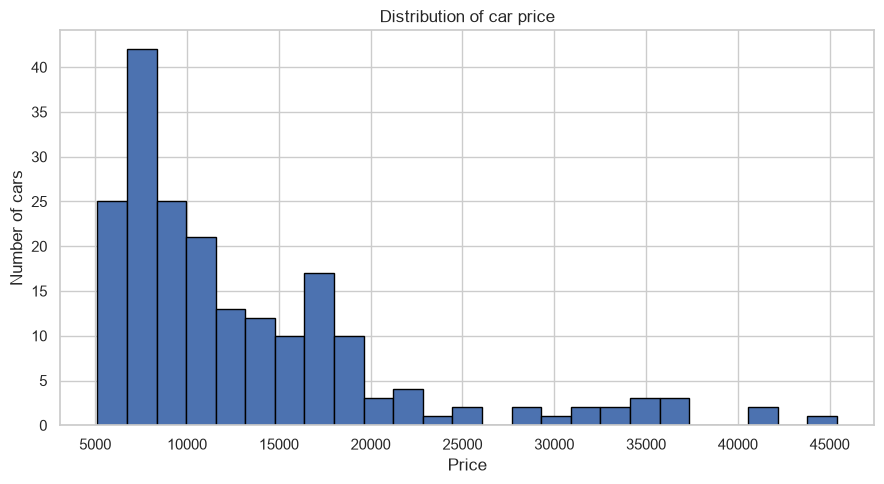

Median price: 10295.0
Mean price: 13207.13


In [8]:
plt.figure(figsize = (9,5))
plt.hist(df["price"], bins = 25 ,edgecolor = "black")
plt.title("Distribution of car price")
plt.xlabel("Price")
plt.ylabel("Number of cars")
plt.tight_layout()
plt.show()

print("Median price:" , round(df["price"].median() , 2))
print("Mean price:" , round(df["price"].mean() , 2))

I compare the mean and median alongside the chart. If the mean is noticeably above the median and the chart has a long right tail, that suggests a few high-priced cars are lifting the average. This is one reason I will report MAE and RMSE later: they describe prediction error in the same price units, though RMSE gives larger errors more weight.

## 5. Check correlations with price

Correlation gives me a quick way to look at the direction and strength of a *linear* relationship between two numeric columns. A positive value means the two variables tend to increase together; a negative value means one tends to decrease as the other increases. Correlation by itself does not prove that one variable causes the other.

In [9]:
numeric_data = df.select_dtypes(include = np.number)

correlation_with_price = numeric_data .corr()["price"].drop("price")

correlation_with_price = correlation_with_price.reindex(correlation_with_price.abs().sort_values(ascending=False).index)

display(correlation_with_price.to_frame("Correlation"))

if not correlation_with_price.empty:

    for feature, r in correlation_with_price.items():

        direction = "positive" if r > 0 else "negative"
        magnitude = abs(r)

        if magnitude >= 0.7:
            strength = "strong"
        elif magnitude >= 0.40:
            strength = "moderate"
        else:
            strength = "weak"

        print(
            f"The correlation of {feature} with price is "
            f"(r = {r:.3f}, which is a {strength} {direction} linear relationship)"
        )

,Correlation
engine-size,0.872335
curb-weight,0.834415
horsepower,0.810533
width,0.751265
highway-mpg,-0.704692
length,0.690628
city-mpg,-0.686571
wheel-base,0.584642
bore,0.543436
normalized-losses,0.203254


The correlation of engine-size with price is (r = 0.872, which is a strong positive linear relationship)
The correlation of curb-weight with price is (r = 0.834, which is a strong positive linear relationship)
The correlation of horsepower with price is (r = 0.811, which is a strong positive linear relationship)
The correlation of width with price is (r = 0.751, which is a strong positive linear relationship)
The correlation of highway-mpg with price is (r = -0.705, which is a strong negative linear relationship)
The correlation of length with price is (r = 0.691, which is a moderate positive linear relationship)
The correlation of city-mpg with price is (r = -0.687, which is a moderate negative linear relationship)
The correlation of wheel-base with price is (r = 0.585, which is a moderate positive linear relationship)
The correlation of bore with price is (r = 0.543, which is a moderate positive linear relationship)
The correlation of normalized-losses with price is (r = 0.203, which

I sort by the absolute correlation so that both strong positive and strong negative relationships appear near the top. The labels in the output are just rules of thumb: a correlation near +1 is strongly positive, a value near -1 is strongly negative, and a value near 0 means little linear association.

### Visualize the strongest numeric relationships

A correlation table compresses each pair into one number. A heatmap gives me a broader view of which numeric features move together, and it can also alert me to predictors that are highly correlated with one another.

---* Heatmap *---


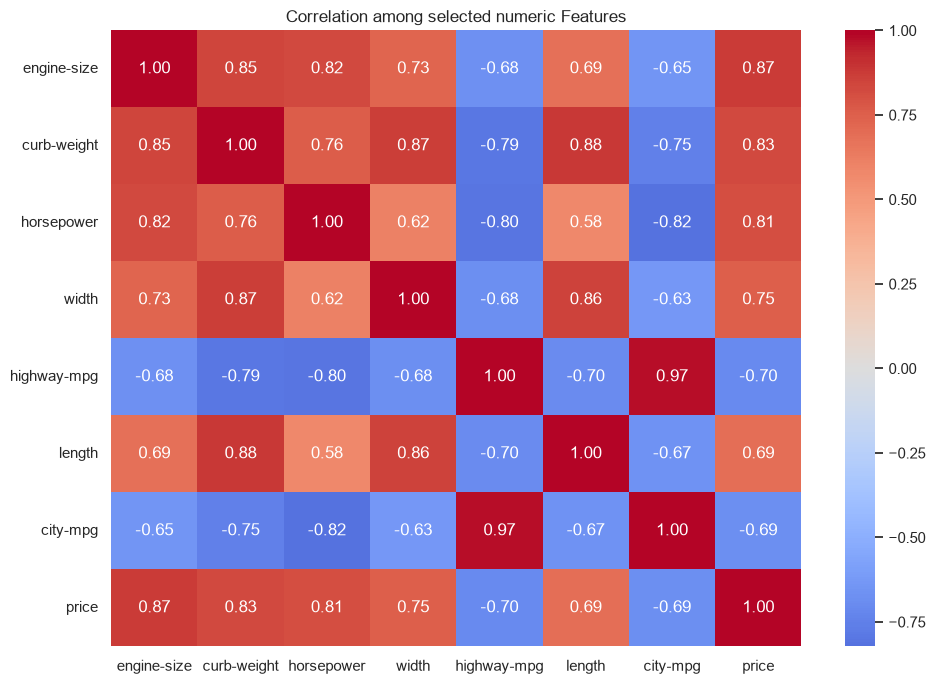

In [10]:
top_feature  = correlation_with_price.head(7).index.tolist()

heatmap_columns = top_feature + ["price"]

correlation_matrix = df[heatmap_columns].corr()
plt.figure(figsize= (10,7))
sns.heatmap(correlation_matrix , cmap= "coolwarm", center = 0 , annot = True , fmt = ".2f")
print("---* Heatmap *---")
plt.title("Correlation among selected numeric Features")
plt.tight_layout()
plt.show()

The heatmap shows that engine-size (0.87), curb-weight (0.83) and horsepower (0.81) have strong positive correlations with price, while highway-mpg (-0.70) and city-mpg (-0.69) have negative correlations. I also observed a very high correlation (0.97) between city-mpg and highway-mpg, indicating potential multicollinearity when using these features together in a regression model.

### Look at individual relationships

I am using regression plots for correaltion features: `engine-size`, `highway-mpg`, `curb-weight` , `horsepower`. The scatter points show individual records, and the line summarizes the overall linear trend.

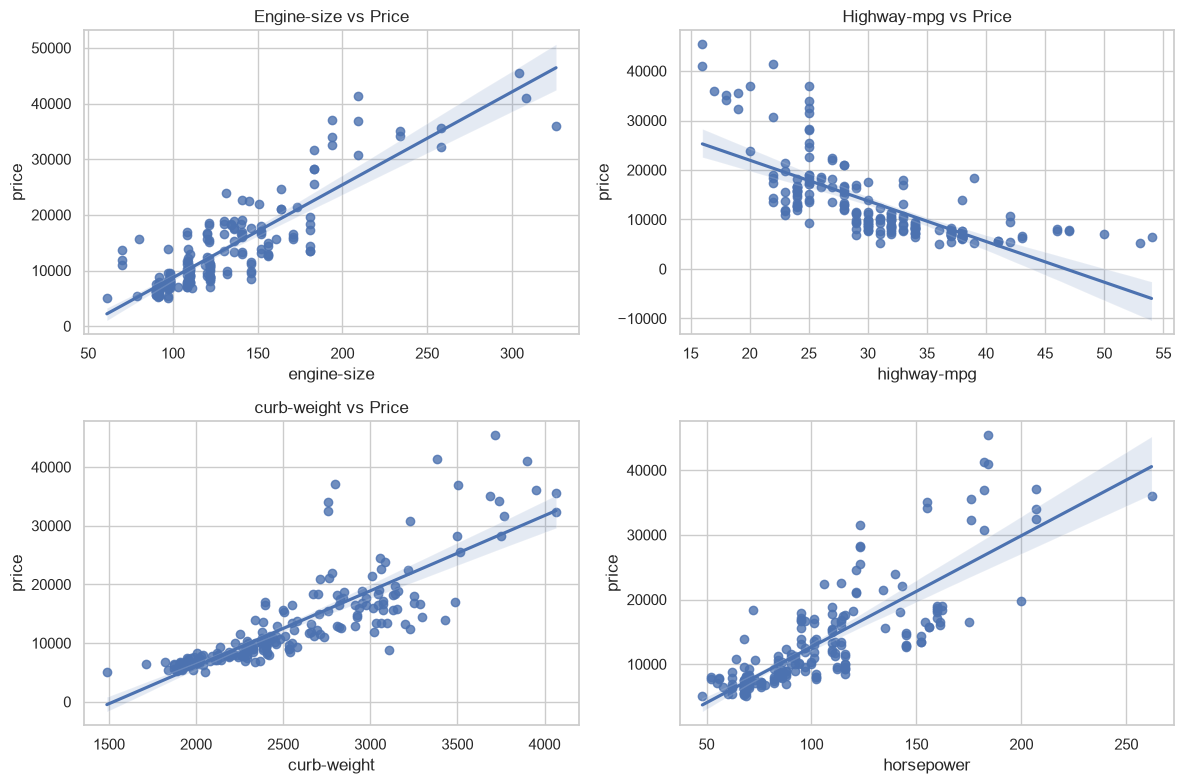

In [11]:
fig, axes = plt.subplots(2,2, figsize=(12,8))

sns.regplot(x = "engine-size" , y = "price" , data = df , ax= axes[0,0])
ax = axes[0,0].set_title("Engine-size vs Price")
sns.regplot(x = "highway-mpg" , y = "price" , data = df , ax= axes[0,1])
ax = axes[0,1].set_title("Highway-mpg vs Price")
sns.regplot(x = "curb-weight" , y = "price" , data = df , ax= axes[1,0])
ax = axes[1,0].set_title("curb-weight vs Price")
sns.regplot(x = "horsepower" , y = "price" , data = df , ax= axes[1,1])
plt.tight_layout()

In [12]:
engine_r = df[["engine-size" ,"price"]].corr().iloc[0,1]
highway_r = df[["highway-mpg" ,"price"]].corr().iloc[0,1]
curb_weight_r = df[["curb-weight" ,"price"]].corr().iloc[0,1]
horsepower_r = df[["horsepower" ,"price"]].corr().iloc[0,1]

print(f"correlation : engine-size vs price = {engine_r:.3f}")
print(f"correlation : highway-mpg vs price = {highway_r:.3f}")
print(f"correlation : curb_weight vs price = {curb_weight_r:.3f}")
print(f"correlation : horsepower vs price = {horsepower_r:.3f}")

correlation : engine-size vs price = 0.872
correlation : highway-mpg vs price = -0.705
correlation : curb_weight vs price = 0.834
correlation : horsepower vs price = 0.811


I compared the trend lines with the correlation values to understand how each feature is associated with price. Engine-size, horsepower and curb-weight show upward trends with positive correlations, indicating that vehicles with larger engines, higher horsepower and greater weight generally tend to have higher prices. In contrast, highway-mpg shows a downward trend with a negative correlation, suggesting that vehicles with better highway fuel efficiency tend to have lower prices in this dataset. These are observations from the dataset and do not necessarily apply to every car.

## 6. Compare prices across categories

Let's check if there is any useful categorical feature which we can make use of in our model. For categorical fields, I compare the price distributions by group rather than calculating a Pearson correlation on the category labels.

In [13]:
drive_wheels_summary = df.groupby("drive-wheels")['price'].agg(car_count = "count" , mean_price = 'mean' , median_price = "median").sort_values("mean_price" , ascending = False)
display(drive_wheels_summary.round(2))

,car_count,mean_price,median_price
drive-wheels,,,
rwd,75,19757.61,16900.0
4wd,8,10241.00,9005.5
fwd,118,9244.78,8192.0


<Axes: xlabel='drive-wheels', ylabel='price'>

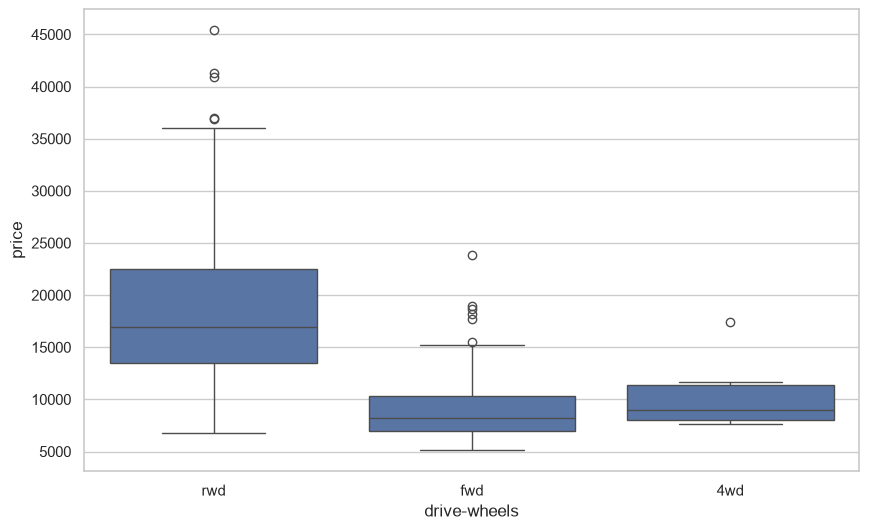

In [14]:
plt.figure(figsize = (10,6))
sns.boxplot(data = df , x= "drive-wheels", y = 'price')

The table compares the number of cars in each group as well as the mean and median prices. The boxplot helps to see whether the groups differ in typical price, spread or outliers. I check group counts too, because a group with only a few cars give as less stable summary

### A simple ANOVA check

Using ANOVA as a way to test whether the mean price differs across multiple groups. I use drive-wheel type as an example. The p-value helps assess evidence of a difference in group means, but it does not tell me which groups differ or whether drive-wheel type causes price to change.

Hypothesis: H0 : μ4WD =μFWD =μRWD ; 
            H1 : At least one group mean is different.

In [15]:
fwd = df.loc[df["drive-wheels"] =="fwd" ,"price"]
rwd = df.loc[df["drive-wheels"] =="rwd" ,"price"]
fourwd = df.loc[df["drive-wheels"] =="4wd" ,"price"]

In [16]:
f_stat, p_value = stats.f_oneway(fwd, rwd, fourwd)

print("F-statistic:", f_stat)
print("P-value:", p_value)
print("-----")
if p_value < 0.05:
    print("We reject the null hypothesis")
else:
    print("We fail to reject the null hypothesis")
print("-----")

F-statistic: 67.95406500780399
P-value: 3.394544357715072e-23
-----
We reject the null hypothesis
-----


The ANOVA test produced an F-statistic of 67.95 and a P-value significantly below 0.05. Therefore, I reject the null hypothesis and conclude that there is a statistically significant difference in average car prices across the drive-wheel categories.

## 7. Exploring Feature Transformations

I explored a few possible feature transformations to understand whether changing the representation of existing variables would make the data easier to interpret. I converted MPG values into L/100 km for metric-unit representation and grouped horsepower into Low, Medium and High categories.

However, I decided to retain the original highway-mpg and horsepower variables for model development. The unit conversion was mainly for interpretation, while grouping horsepower would result in losing some of the detailed numerical information. I also avoided including both city and highway fuel economy together because they are highly correlated.

In [17]:
feature_demo = df[["city-mpg", "highway-mpg", "horsepower", "fuel-type"]].copy()
feature_demo["city-L/100km"] = 235 / feature_demo["city-mpg"]
feature_demo["highway-L/100km"] = 235 / feature_demo["highway-mpg"]
feature_demo["horsepower-band"] = pd.cut(feature_demo["horsepower"], bins = 3 , labels = ["Low","Medium","High"])
display(feature_demo.head())

,city-mpg,highway-mpg,horsepower,fuel-type,city-L/100km,highway-L/100km,horsepower-band
0,21,27,111.0,gas,11.190476,8.703704,Low
1,21,27,111.0,gas,11.190476,8.703704,Low
2,19,26,154.0,gas,12.368421,9.038462,Medium
3,24,30,102.0,gas,9.791667,7.833333,Low
4,18,22,115.0,gas,13.055556,10.681818,Low


MPG and litres per 100 km describe fuel economy in opposite directions, so the transformed L/100 km value is useful when a reader is more familiar with that unit. The horsepower bands simplify a continuous measure into low, medium, and high groups, although they lose some detail compared with using the original number. I keep the original numeric horsepower for the regression model.

In [18]:
fuel_type_indicators = pd.get_dummies(df[["fuel-type"]], prefix="fuel", dtype=int)
display(pd.concat([df[["fuel-type"]].head(), fuel_type_indicators.head()], axis=1))

,fuel-type,fuel_diesel,fuel_gas
0,gas,0,1
1,gas,0,1
2,gas,0,1
3,gas,0,1
4,gas,0,1


One-hot encoding gives each fuel type its own 0/1 indicator column. That lets a regression model use category information without pretending that categories have a natural numeric order. In the modeling pipeline below, I use **OneHotEncoder** so the same transformation is applied consistently to both training and test data.

## 8. Prepare the modeling data

I choose the target and predictors based on the question and the patterns explored above. Engine size, horsepower, weight, highway fuel economy, and dimensions describe vehicle specifications. Make, fuel type, body style, drive wheels, and aspiration add category information that may also be related to price.

I split the data **before fitting imputers, scalers, or encoders**. This is important because those preprocessing steps should learn from the training set only.

In [19]:
target = "price"
numeric_features = [
    "engine-size", "horsepower", "curb-weight", "highway-mpg",
    "wheel-base", "width", "length"
]
categorical_features = ["make", "fuel-type", "body-style", "drive-wheels", "aspiration"]
feature_columns = numeric_features + categorical_features

X = df[feature_columns].copy()
y = df[target].copy()

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.2, random_state = 42)
print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])
print("Predictor columns before encoding:" ,len(feature_columns))

Training rows: 160
Testing rows: 41
Predictor columns before encoding: 12


I have divided the dataset into 80% training data and 20% testing data. The training data will be used to train the model, while the testing data will be used to evaluate how well the model predicts prices on unseen records. I have used random_state=42 so that the data split remains the same every time I run the code.

### Build preprocessing pipelines

Numeric fields need missing-value handling and scaling. Categorical fields need missing-value handling and one-hot encoding. I put these steps in a `ColumnTransformer` so the exact same rules can be reused by different models.

In [20]:
numeric_preprocessing = Pipeline(steps= [
    ("impute" , SimpleImputer(strategy = "median")),
    ("scaling", StandardScaler())
])

categorical_preprocessing = Pipeline(steps = [
    ("impute", SimpleImputer(strategy = "most_frequent")),
    ("encoder" , OneHotEncoder(handle_unknown = "ignore"))
])

preprocessor = ColumnTransformer(transformers = [
    ("numeric" , numeric_preprocessing , numeric_features),
    ("categorical" , categorical_preprocessing , categorical_features)
])

I use the median for missing numeric values and the most common value for missing categories. `StandardScaler` puts numeric features on comparable scales, which is especially useful for a regularized model such as Ridge. `handle_unknown="ignore"` also prevents the model from failing if the test set contains a category not seen during training.

## 9. Train a simple regression model first

I start with `engine-size` as the only predictor. A one-feature model is easy to interpret and gives me a baseline for whether adding more information is helping.

In [21]:
simple_model = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("model", LinearRegression())
])

simple_model.fit(X_train[["engine-size"]], y_train)

simple_train_r2 = simple_model.score(X_train[["engine-size"]], y_train)
simple_test_r2 = simple_model.score(X_test[["engine-size"]], y_test)
print("Number of training records:", X_train[["engine-size"]].shape[0])
print("Number of testing records:", X_test[["engine-size"]].shape[0])
print("Number of predictors:", X_train[["engine-size"]].shape[1])
print(f"Simple model training R²: {simple_train_r2:.3f}")
print(f"Simple model test R²: {simple_test_r2:.3f}")

Number of training records: 160
Number of testing records: 41
Number of predictors: 1
Simple model training R²: 0.757
Simple model test R²: 0.725


R² describes how much of the variation in price the model explains relative to a mean-only prediction. A higher value is generally better, but I compare training and test scores rather than relying on training R² alone. A large gap can be a warning that the model fits the training records better than unseen records.

### Try a curved relationship

A straight line may not capture every pattern between engine size and price. Polynomial regression adds a squared version of the predictor, which allows a curve while keeping the model example small.

In [22]:
polynomial_model = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("polynomial", PolynomialFeatures(degree=2, include_bias=False)),
    ("model", LinearRegression())
])

polynomial_model.fit(X_train[["engine-size"]], y_train)

poly_train_r2 = polynomial_model.score(X_train[["engine-size"]], y_train)
poly_test_r2 = polynomial_model.score(X_test[["engine-size"]], y_test)
print("Number of training records:", X_train[["engine-size"]].shape[0])
print("Number of testing records:", X_test[["engine-size"]].shape[0])
print("Number of predictors:", X_train[["engine-size"]].shape[1])
print(f"Degree-2 polynomial training R²: {poly_train_r2:.3f}")
print(f"Degree-2 polynomial test R²: {poly_test_r2:.3f}")

Number of training records: 160
Number of testing records: 41
Number of predictors: 1
Degree-2 polynomial training R²: 0.757
Degree-2 polynomial test R²: 0.724


The polynomial model has more flexibility than the straight-line model. If its training score improves but the test score does not, that is a sign the extra flexibility may not generalize well. A higher polynomial degree is not automatically better, especially with a small dataset.

## 10. Use multiple predictors

A car price is unlikely to depend on just one specification, so I train a multiple linear regression model with the selected numeric and categorical features. The preprocessing steps stay inside the pipeline so model fitting and prediction use the same transformations.

In [23]:
multiple_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

multiple_model.fit(X_train, y_train)

multiple_train_r2 = multiple_model.score(X_train, y_train)
multiple_test_r2 = multiple_model.score(X_test, y_test)
print("Number of training records:", X_train.shape[0])
print("Number of testing records:", X_test.shape[0])
print("Number of predictors:", X_train.shape[1])
print(f"Multiple regression training R²: {multiple_train_r2:.3f}")
print(f"Multiple regression test R²: {multiple_test_r2:.3f}")

Number of training records: 160
Number of testing records: 41
Number of predictors: 12
Multiple regression training R²: 0.942
Multiple regression test R²: 0.915


This model uses several specifications at the same time. It may capture more of the variation in price than the one-feature model, but extra predictors also add complexity. I judge the result using test performance and cross-validation, not by assuming that a model must improve simply because it has more features.

## 11. Cross-validation and Ridge regression

A single train/test split can give a result that depends on which cars happen to land in the test set. I use five-fold cross-validation on the training data to compare model stability. Ridge regression adds a penalty to large coefficients, which can help when predictors overlap or the model has many encoded categories.

In [24]:
# Define 5-fold cross-validation strategy
cv_strategy = KFold(n_splits=5, shuffle=True, random_state=42)

simple_cv_scores = cross_val_score(
    simple_model, X_train[["engine-size"]], y_train,
    cv=cv_strategy, scoring="r2")

poly_cv_scores = cross_val_score(
    polynomial_model, X_train[["engine-size"]], y_train,
    cv=cv_strategy, scoring="r2")

multiple_cv_scores = cross_val_score(
    multiple_model, X_train, y_train,
    cv=cv_strategy, scoring="r2")

ridge_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", Ridge())])

alpha_grid = {"model__alpha": [0.1, 1, 10, 100]}

ridge_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=alpha_grid,
    cv=cv_strategy,
    scoring="r2",
    n_jobs=-1)

ridge_search.fit(X_train, y_train)

best_ridge_model = ridge_search.best_estimator_

cv_summary = pd.DataFrame([
    { "model": "Simple linear regression",
        "mean_cv_r2": simple_cv_scores.mean(),
        "std_cv_r2": simple_cv_scores.std()},
    
    { "model": "Degree-2 polynomial regression",
        "mean_cv_r2": poly_cv_scores.mean(),
        "std_cv_r2": poly_cv_scores.std()},
    
    {"model": "Multiple linear regression",
        "mean_cv_r2": multiple_cv_scores.mean(),
        "std_cv_r2": multiple_cv_scores.std()},
    
    {"model": "Tuned Ridge regression",
        "mean_cv_r2": ridge_search.best_score_,
        "std_cv_r2": ridge_search.cv_results_["std_test_score"][
            ridge_search.best_index_]}]).sort_values("mean_cv_r2", ascending=False)

display(cv_summary.round(3))

print("Best Ridge alpha:", ridge_search.best_params_["model__alpha"])

,model,mean_cv_r2,std_cv_r2
3,Tuned Ridge regression,0.843,0.058
2,Multiple linear regression,0.792,0.111
0,Simple linear regression,0.701,0.149
1,Degree-2 polynomial regression,0.686,0.145


Best Ridge alpha: 1


I used five-fold cross-validation to compare how consistently the models perform on different portions of the training data. I also introduced Ridge Regression to control large coefficients and help manage overlapping predictors. Using GridSearchCV, I tested different alpha values and selected alpha = 1 based on the highest average cross-validation R². Ridge achieved a mean CV R² of 0.843, compared with 0.792 for Multiple Linear Regression, and also showed lower variation across folds. The test data remains separate for final model evaluation.

## 12. Compare predictions on the held-out test set

I compare the models with the same test records. Along with R², I use mean absolute error (MAE) and root mean squared error (RMSE). Both error measures are in the same units as `price`; MAE is the average absolute miss, while RMSE penalizes larger misses more heavily.

In [25]:
baseline_model = DummyRegressor(strategy="median")
baseline_model.fit(X_train[["engine-size"]], y_train)

models_to_evaluate = [
    ("Median baseline", baseline_model, X_train[["engine-size"]], X_test[["engine-size"]]),
    ("Simple linear regression", simple_model, X_train[["engine-size"]], X_test[["engine-size"]]),
    ("Degree-2 polynomial regression", polynomial_model, X_train[["engine-size"]], X_test[["engine-size"]]),
    ("Multiple linear regression", multiple_model, X_train, X_test),
    ("Tuned Ridge regression", best_ridge_model, X_train, X_test)
]

results = []
for model_name, model, train_features, test_features in models_to_evaluate:
    train_predictions = model.predict(train_features)
    test_predictions = model.predict(test_features)
    results.append({
        "model": model_name,
        "train_r2": r2_score(y_train, train_predictions),
        "test_r2": r2_score(y_test, test_predictions),
        "test_mae": mean_absolute_error(y_test, test_predictions),
        "test_rmse": np.sqrt(mean_squared_error(y_test, test_predictions))
    })

model_results = pd.DataFrame(results).sort_values("test_rmse")
display(model_results.round(2))

,model,train_r2,test_r2,test_mae,test_rmse
3,Multiple linear regression,0.94,0.91,2125.21,3228.17
4,Tuned Ridge regression,0.93,0.90,2242.28,3500.97
1,Simple linear regression,0.76,0.72,4176.27,5804.91
2,Degree-2 polynomial regression,0.76,0.72,4178.31,5810.21
0,Median baseline,-0.10,-0.22,7953.17,12226.27


I use the median baseline as a sanity check: a useful model should generally do better than simply predicting the training-set median for every test car. Lower MAE and RMSE mean smaller errors. Higher R² usually means the model explains more variation, but the practical size of the price error matters too.

The table is a comparison on one holdout split, so I do not treat small differences as definitive. For choosing the Ridge penalty, I rely on cross-validation performed on the training set.

### Plot actual prices against Ridge predictions

The dashed diagonal marks perfect predictions. Points close to that line are estimated more accurately; points well above or below it show larger errors.

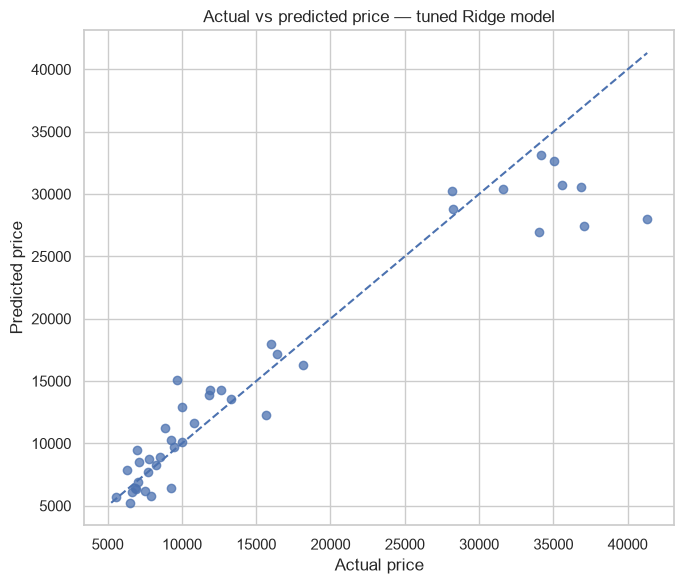

Ridge test R²: 0.900
Ridge test MAE: 2242.28
Ridge test RMSE: 3500.97


In [26]:
ridge_test_predictions = best_ridge_model.predict(X_test)
plot_min = min(float(y_test.min()), float(ridge_test_predictions.min()))
plot_max = max(float(y_test.max()), float(ridge_test_predictions.max()))

plt.figure(figsize=(7, 6))
plt.scatter(y_test, ridge_test_predictions, alpha=0.75)
plt.plot([plot_min, plot_max], [plot_min, plot_max], linestyle="--")
plt.xlabel("Actual price")
plt.ylabel("Predicted price")
plt.title("Actual vs predicted price — tuned Ridge model")
plt.tight_layout()
plt.show()

ridge_mae = mean_absolute_error(y_test, ridge_test_predictions)
ridge_rmse = np.sqrt(mean_squared_error(y_test, ridge_test_predictions))
ridge_r2 = r2_score(y_test, ridge_test_predictions)
print(f"Ridge test R²: {ridge_r2:.3f}")
print(f"Ridge test MAE: {ridge_mae:.2f}")
print(f"Ridge test RMSE: {ridge_rmse:.2f}")

I look for points clustered around the diagonal and check the numeric metrics together. R² describes fit relative to a simple mean prediction, while MAE and RMSE describe the size of the errors. None of these metrics alone tells the full story, particularly because this is a small dataset with a wide range of car prices.

## 13. Final summary

I finish by collecting the result from the tuned Ridge model in one place. The notebook calculates the values when the code is run, so I do not need to hard-code a score that may change with library versions or a different train/test split.

In [27]:
print("Project summary")
print("--------------")
print(f"Rows used for analysis: {len(df)}")
print(f"Predictor fields used before encoding: {len(feature_columns)}")
print(f"Selected Ridge alpha from cross-validation: {ridge_search.best_params_['model__alpha']}")
print(f"Best cross-validation R²: {ridge_search.best_score_:.3f}")
print(f"Held-out test R²: {ridge_r2:.3f}")
print(f"Held-out test MAE: {ridge_mae:.2f}")
print(f"Held-out test RMSE: {ridge_rmse:.2f}")

Project summary
--------------
Rows used for analysis: 201
Predictor fields used before encoding: 12
Selected Ridge alpha from cross-validation: 1
Best cross-validation R²: 0.843
Held-out test R²: 0.900
Held-out test MAE: 2242.28
Held-out test RMSE: 3500.97


### Conclusion:

The tuned Ridge Regression model achieved a cross-validation R² of 0.843 and a test R² of 0.900. Although Multiple Linear Regression performed slightly better on the test set, Ridge showed more consistent performance across validation folds. Overall, both models showed good predictive potential, although testing on a larger dataset would help validate their performance.